# Assignment: Pitfalls of model evaluation and feature selection.

**Course:** Quantitative Data Analysis (INFOMQUDA)  
**Environment:** Google Colab (CPU is sufficient)  
**Datasets:** Bacterial genomes (in preparation for a database publication)

---

In this practical, we will focus on a classification problem. We will distinguish bacteria that live on plant **roots** from those that live in **soil**, using features derived from their genomes.

We are interested in understanding what helps bacteria survive and colonise plant roots, with the longer-term goal of engineering bacteria with useful agricultural properties.

Since lab experiments are expensive, we would like to narrow down which features are worth investigating.

---

## Background

The data we will work with today comes predominantly from whole-genome sequencing. This gives us information about the genes of bacteria found in different environments or associated with different hosts.

From a genome, we can identify protein-coding genes and translate their DNA sequences into protein sequences. We focus on proteins because they carry out many of the functions that allow bacteria to interact with their environment. Recent research has shown the relevance of these functional capacities for bacterial recruitment into plant roots (Selten et al., 2026).

To infer protein function, we can compare a protein sequence with databases containing proteins with known or predicted functions.

One such resource is [KEGG Orthology](https://www.genome.jp/kegg/ko.html), which groups genes and proteins according to their inferred functions. Our first features are binary: 1 if a KO is present in a genome, 0 if it is absent.

Previous research has identified a set of KOs associated with root microbiomes (Selten et al., 2026). We will examine how useful these features are for prediction and how much we can conclude from their importance in a model.

---

## Getting the data

The data has been already prepared for you. You need to download them into your google drive: https://filesender.surf.nl/?s=download&token=7c9898bc-3052-4f64-8d93-f23981ceb68a

**Files needed:** `metadata_bacteria_study_source_checked.tsv`, `KO_binary_bacteria.tsv.gz` and `KO_binary_bacteria.tsv.gz`.

---

## 0. Import packages

In [1]:
%pip -q install nuee

import nuee
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score
import plotly.express as px
from scipy.spatial.distance import pdist, squareform
import random
import torch
import torch.nn as nn
import shap
import gzip

from google.colab import drive
drive.mount('/content/drive/')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.2/140.2 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 24.9 MB/s eta 0:00:00
Mounted at /content/drive/


In [2]:
def classification_scores(y_true, predictions):
    return {
        "Balanced accuracy": balanced_accuracy_score(y_true, predictions),
        "Root precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Root recall": recall_score(
            y_true, predictions, zero_division=0
        )
    }


def evaluate_logistic_regression(model, X):
    results = []

    for name in ["ID test", "Study OOD", "Phylum OOD"]:
        predictions = model.predict(X.loc[splits[name]])

        results.append({
            "Test set": name,
            **classification_scores(y.loc[splits[name]], predictions)
        })

    return pd.DataFrame(results).set_index("Test set")

## 1. Examining the data

Let's first look at the data we have. We will examine the number of genomes, their KO features, and how samples are distributed across environments, studies, and taxonomic groups.

We have two datasets:
1. metadata describing each bacterial genome
2. large binary matrix showing which KOs are present in the genomes.

An important terminology explanation before we start. Bacteria are classified into groups based on their evolutionary relationships, similar to branches of a family tree. A **phylum** is a broad group, while a **family** contains more closely related bacteria. Related bacteria often share many genes because of their common ancestry. This is comparable to you being more related to your family then to people in general and still being more related toother people then to zebras.

In [3]:
# 1.1 Loading the data
folder = "/content/drive/MyDrive/Colab Notebooks/" #Change for your path
metadata = pd.read_csv(folder + "metadata_bacteria_study_source_checked.tsv", sep="\t")
label = metadata["Compartment"].value_counts()

# Load binary KO values to reduce RAM usage
with gzip.open(folder + "KO_binary_bacteria.tsv.gz", "rt") as file:
    ko_columns = file.readline().rstrip("\n").split("\t")

ko_data = pd.read_csv(
    folder + "KO_binary_bacteria.tsv.gz",
    sep="\t",
    dtype={
        col: ("string" if col == "isolate" else "uint8")
        for col in ko_columns
    }
)

print("Isolates:", len(metadata))
print("KO features:", len(ko_data.columns) - 1)
print(f"Soil: {label['Soil']:,} | Root: {label['Root']:,}")

print("Phyla:", metadata["Phylum"].nunique())
print("Families:", metadata["Family"].nunique())
print("Isolates without a Study value:", metadata["Study"].isna().sum())

metadata.head()

Isolates: 50398
KO features: 10541
Soil: 38,341 | Root: 12,057
Phyla: 100
Families: 1516
Isolates without a Study value: 1199


,isolate,Soil.type.host.species,Compartment,Data,Study,Completeness,Contamination,label,Domain,Phylum,Class,Order,Family,Genus,Species
0,2832004796,Acanthus ilicifolius,Root,IMG,Gs0139235,100.00,0.30,1,Bacteria,Actinobacteriota,Actinomycetia,Mycobacteriales,Micromonosporaceae,Micromonospora,Micromonospora endophytica
1,158416,Acanthus ilicifolius,Root,BacDive,NaN,98.36,0.28,1,Bacteria,Firmicutes,Bacilli,Bacillales_B,DSM-1321,Bacillus_BN,Bacillus_BN acanthi
2,2844163670,Acer pseudoplatanus,Root,IMG,Gs0140171,97.50,0.79,1,Bacteria,Proteobacteria,Alphaproteobacteria,Rhizobiales,Rhizobiaceae,Ensifer,Ensifer adhaerens_A
3,GCA_041021105.1,Adonis amurensis,Root,NCBI_GCA,BioSample:SAMN42231578,100.00,3.31,1,Bacteria,Actinobacteriota,Actinomycetia,Streptomycetales,Streptomycetaceae,Streptomyces,NaN
4,3300027312_8,Agave,Root,IMG,Gs0053055,85.91,0.28,1,Bacteria,Proteobacteria,Alphaproteobacteria,Rhizobiales,Rhizobiaceae,Agrobacterium,Agrobacterium pusense


In [4]:
ko_data.head()

,isolate,K00001,K00003,K00004,K00005,K00007,K00008,K00009,K00010,K00012,...,K28298,K28299,K28300,K28317,K28320,K28321,K28322,K28323,K28327,K28329
0,2832004796,0,1,1,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,158416,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,2844163670,0,1,1,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
3,GCA_041021105.1,0,1,1,0,0,0,0,1,1,...,0,0,0,0,0,1,0,0,0,0
4,3300027312_8,0,1,1,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# 1.2. Loading list of previously identified important features
ko_selected_features = pd.read_csv(folder + "KO_266.csv", sep=";")

ko_selected_features = ko_selected_features[ko_selected_features["KO"].isin(ko_data.columns)]
selected_kos = ko_selected_features["KO"].tolist()

X = ko_data[["isolate"] + selected_kos].set_index("isolate")

print("Selected KOs:", len(selected_kos))
print("KO matrix:", X.shape)
X.head()

Selected KOs: 252
KO matrix: (50398, 252)


,K00035,K01179,K01975,K03336,K05350,K05841,K07104,K09565,K10117,K10560,...,K11604,K12989,K13598,K15063,K16560,K17229,K18588,K19687,K20531,K22215
isolate,,,,,,,,,,,,,,,,,,,,,
2832004796,0,1,1,1,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
158416,0,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2844163670,1,1,1,1,0,0,1,0,1,1,...,1,1,1,0,1,0,1,1,1,1
GCA_041021105.1,0,1,1,1,1,0,1,0,1,1,...,0,0,1,0,0,0,0,0,0,0
3300027312_8,1,0,1,1,0,0,1,0,1,1,...,1,1,1,0,1,0,1,0,0,1


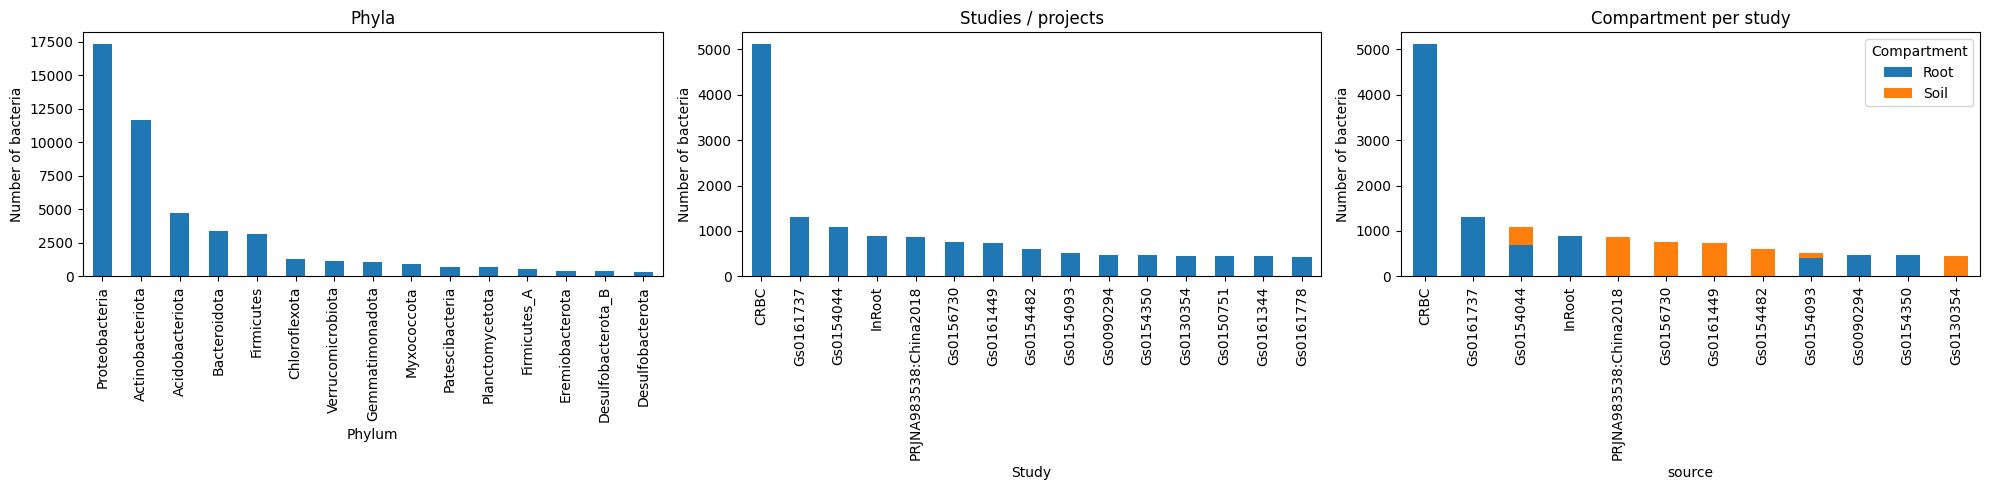

In [6]:
# 1.3. Plot the data per metadata categories
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Phyla
metadata["Phylum"].value_counts().head(15).plot.bar(ax=axes[0], title="Phyla")

# 2. Studies
studies = metadata.loc[~metadata["Study"].fillna("").str.startswith("BioSample:"), "Study"]

studies.value_counts().head(15).plot.bar(ax=axes[1], title="Studies / projects")

# 3. Root vs Soil by data source
source_data = metadata.assign(source=metadata["Study"].str.split(",")).explode("source")

source_data["source"] = source_data["source"].str.strip()

pd.crosstab(
    source_data["source"], source_data["Compartment"]
).loc[source_data["source"].value_counts().head(12).index].plot.bar(
    stacked=True, ax=axes[2], title="Compartment per study"
)

for ax in axes:
    ax.set_ylabel("Number of bacteria")
    ax.tick_params(axis="x", labelrotation=90)

plt.tight_layout()
plt.show()

### Questions 1

1. Are Root and Soil samples equally represented? Why might that matter for model evaluation?
2. Do all studies contribute similar numbers of genomes?
3. Looking at the plots, can you think of a way a model might predict Root versus Soil without actually learning anything about root colonisation?

## 2. Covariate analysis

Before building a classifier, let's check what explains variation in the functional, KO profiles.

We know whether each genome comes from Root or Soil, but we also know its study and phylum.

We'll use PERMANOVA with Jaccard distances to compare how much variation is associated with each variable.

To keep this manageable, we use the selected KO features and retain studies and phyla with enough samples from both environments.

In [7]:
# 2.1. Filter the data
# Select genomes with known study and phylum
filtered_metadata = metadata.set_index("isolate").loc[X.index].dropna(subset=["Study", "Phylum"])

# Keep studies and phyla with at least 10 Root and 10 Soil genomes
study = pd.crosstab(filtered_metadata.Study, filtered_metadata.Compartment)
phylum = pd.crosstab(filtered_metadata.Phylum, filtered_metadata.Compartment)

filtered_metadata = filtered_metadata[
    filtered_metadata.Study.isin(study.index[study.min(axis=1) >= 10]) &
    filtered_metadata.Phylum.isin(phylum.index[phylum.min(axis=1) >= 10])
]

# Remove rare and nearly universal KOs (e.g., if a feature has a 0 in all samples we want to explude it, same if it has one in all samples)
X_perm = X.loc[filtered_metadata.index]
X_perm = X_perm.loc[:, X_perm.mean().between(0.05, 0.95)]


print("Genomes:", len(filtered_metadata), "| KOs:", X_perm.shape[1])

Genomes: 2753 | KOs: 156


In [8]:
# 2.2. Run analysis
# Jaccard distance
D = squareform(pdist(X_perm.to_numpy(dtype=bool), metric="jaccard"))

# STUDENT CODE HERE
# 1. define D in terms of euclidean distance

# STUDENT CODE HERE

models = {
    "Compartment only": ["Compartment"],
    "Study only": ["Study"],
    "Phylum only": ["Phylum"],
    "Compartment + Study": ["Study", "Compartment"],
    "Compartment + Phylum": ["Phylum", "Compartment"],
    "Compartment + Study + Phylum": ["Study", "Phylum", "Compartment"]
}

results = []

for name, factors in models.items():
    result = nuee.adonis2(D, filtered_metadata[factors],permutations=199, random_state=42)

    tested_factor = "Compartment" if "Compartment" in factors else factors[-1]
    row = result.loc[tested_factor, ["R2", "F", "Pr(>F)"]]
    results.append([name, tested_factor, *row])

summary = pd.DataFrame(results,columns=["Model", "Factor tested", "R²", "Pseudo-F", "p-value"])

display(summary.round(4))

,Model,Factor tested,R²,Pseudo-F,p-value
0,Compartment only,Compartment,0.0132,36.7410,0.005
1,Study only,Study,0.0855,36.6673,0.005
2,Phylum only,Phylum,0.2874,58.0051,0.005
3,Compartment + Study,Compartment,0.0124,37.7405,0.005
4,Compartment + Phylum,Compartment,0.0049,18.9062,0.005
5,Compartment + Study + Phylum,Compartment,0.0055,21.7667,0.005


## Questions 2

1. Which variable explains the most variation in KO composition: compartment, study, or phylum?

2. What happens to the contribution of compartment when study or phylum is included in the model? What cosequences can this have?

3. We used jaccard distance. What implication does that have? What would happen if we used Euclidean distance?

4. Could we use ANOVA to investigate covariates? How would that work? What would we need to keep in mind?

Remember that PERMANOVA tells us about differences in overall KO composition. It doesn't tell us which individual KOs are biologically responsible.

## 3. Linear Classification Models

Now let's try predicting Root versus Soil.

We'll start with logistic regression, a simple linear classifier. It learns a coefficient for each KO, which tells us how that feature contributes to the prediction.

But before training, we need to decide how to evaluate our models.

A random train/test split is useful, but based on what we have seen above, it might overestimate the actual relationship between the response variable and the features. Generally, random split doesn't tell us whether the model has learned robust biological information that generalise on bacteria from a completely different study or an unfamiliar evolutionary lineage.

So we'll use three test sets:

1. **ID test**: genomes randomly held out from the training pool.

2. **Study OOD**: genomes from studies the model has never seen.

3. **Phylum OOD**: genomes from phyla excluded from training, drawn from studies represented in the training data.

OOD means out of distribution.

We'll compare balanced accuracy, Root precision, and Root recall. These are particularly useful when the two classes aren't equally common.

In [9]:
# 3.1. Find the right subsets in the metadata
heldout_studies = ["Gs0103573", "Gs0150749", "Gs0133685"]

heldout_phyla = [
    "Fibrobacterota",
    "Deinococcota",
    "Bdellovibrionota",
    "Campylobacterota",
    "Spirochaetota"
]

# Align metadata with KO matrix
genomes = metadata.set_index("isolate").loc[ko_data["isolate"]].copy()
genomes = genomes.dropna(subset=["Study", "Phylum", "label"])

# Root = 1, Soil = 0
y = genomes["label"].astype(int)

# 1. Hold out the three studies completely
study_mask = genomes["Study"].isin(heldout_studies)
study_ood_idx = genomes.index[study_mask]

# 2. Reserve the five phyla from all remaining studies
phylum_mask = genomes["Phylum"].isin(heldout_phyla)

# 3. Eligible training/ID pool: neither held-out studies nor phyla
train_pool = genomes.loc[~study_mask & ~phylum_mask]

# 4. Random in-distribution split
train_idx, id_idx = train_test_split(
    train_pool.index,
    test_size=0.2,
    stratify=y.loc[train_pool.index],
    random_state=42
)

# 5. Phylum OOD: only studies actually represented in training
phylum_ood_idx = genomes.index[
    ~study_mask
    & phylum_mask
    & genomes["Study"].isin(genomes.loc[train_idx, "Study"])
]

splits = {
    "Train": train_idx,
    "ID test": id_idx,
    "Study OOD": study_ood_idx,
    "Phylum OOD": phylum_ood_idx
}

# Summary
summary = pd.DataFrame([
    {
        "Set": name,
        "Root": (y.loc[idx] == 1).sum(),
        "Soil": (y.loc[idx] == 0).sum(),
        "Total": len(idx),
        "Studies": genomes.loc[idx, "Study"].nunique(),
        "Phyla": genomes.loc[idx, "Phylum"].nunique()
    }
    for name, idx in splits.items()
])

display(summary)

# Check that the four splits do not overlap
for i, name_a in enumerate(splits):
    for name_b in list(splits)[i + 1:]:
        assert set(splits[name_a]).isdisjoint(splits[name_b])

assert set(genomes.loc[splits["Phylum OOD"], "Study"]).issubset(
    set(genomes.loc[splits["Train"], "Study"])
)

,Set,Root,Soil,Total,Studies,Phyla
0,Train,9268,29354,38622,15782,85
1,ID test,2317,7339,9656,4334,69
2,Study OOD,233,212,445,3,17
3,Phylum OOD,111,102,213,61,5


In [10]:
# 3.2. Make the splits
# All KOs, aligned with the metadata
all_kos = ko_data.set_index("isolate").loc[genomes.index]

# STUDENT CODE HERE
# If we have a feature (KO) that is 0 in all samples or 1 in
# all samples it is not informative and adds noise.
# We want to keep KOs present in 5–95% of training genomes.
# 1. calculate prevalence of each KO in the training set (the proportion of genomes containing that KO).
# 2. create a list called "valid_kos" containing the KO identifiers with a prevalence between 5-95%

# STUDENT CODE HERE

# Selected KOs passing the same filter
selected_kos = [
    ko for ko in ko_selected_features["KO"]
    if ko in valid_kos
]
selected_kos = list(dict.fromkeys(selected_kos))

# Five random subsets, each with the same number of KOs as the selected set
rng = np.random.default_rng(42)

feature_sets = {
    "All KOs": valid_kos,
    "Selected KOs": selected_kos
}

for i in range(5):
    feature_sets[f"Random {i+1}"] = rng.choice(
        valid_kos,
        size=len(selected_kos),
        replace=False
    ).tolist()

display(pd.Series({
    name: len(kos)
    for name, kos in feature_sets.items()
}, name="Number of KOs"))

,Number of KOs
All KOs,4570
Selected KOs,161
Random 1,161
Random 2,161
Random 3,161
Random 4,161
Random 5,161


In [11]:
#3.3. Can we predict bacterial enviroment using the published KOs?
X = all_kos[feature_sets["Selected KOs"]]

## STUDENT TASK ##
# 1. change the regularisation of the model and examine the plot
model_selected = LogisticRegression(
    penalty="l2",  # Change to "l1" for L1 regularisation
    C=0.01,        # Change to 0.1 or higher; smaller c means stronger regularisation
    solver="liblinear",
    class_weight="balanced",
    max_iter=1000
)

model_selected.fit(
    X.loc[splits["Train"]],
    y.loc[splits["Train"]]
)

display(evaluate_logistic_regression(model_selected, X).round(3))

print("Nonzero coefficients:", (model_selected.coef_[0] != 0).sum())

coefficients = pd.DataFrame(
    [model_selected.coef_[0]],
    columns=X.columns,
    index=["Coefficient"]
)

fig = px.imshow(
    coefficients,
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    aspect="auto",
    width=2000,
    height=320
)

fig.update_xaxes(
    tickmode="array",
    tickvals=X.columns.tolist(),
    ticktext=X.columns.tolist()
)

fig.update_layout(
    title="Logistic regression coefficients — selected KOs",
    xaxis_tickangle=90,
    xaxis_tickfont=dict(size=6)
)

fig.show()

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Balanced accuracy,Root precision,Root recall
Test set,,,
ID test,0.722,0.458,0.710
Study OOD,0.665,0.748,0.524
Phylum OOD,0.598,0.867,0.234


Nonzero coefficients: 161


In [12]:
# 3.4. What if we use all available KOs?
X = all_kos[feature_sets["All KOs"]]

model_all = LogisticRegression(
    penalty="l2",
    C=0.01,
    solver="liblinear",
    class_weight="balanced",
    max_iter=1000
)

model_all.fit(
    X.loc[splits["Train"]],
    y.loc[splits["Train"]]
)

display(evaluate_logistic_regression(model_all, X).round(3))

print("Nonzero coefficients:", (model_all.coef_[0] != 0).sum())

# STUDENT CODE HERE
# 1. Rank KOs by absolute coefficient magnitude
# 2. Create a list called "top_250_kos" containing the identifiers of the 250 highest-ranked KOs

# STUDENT CODE HERE

# Compare the top 250 with the selected KO set
shared_kos = set(top_250_kos) & set(feature_sets["Selected KOs"])

overlap_table = pd.DataFrame([{
    "Top KOs": len(top_250_kos),
    "Selected KOs": len(feature_sets["Selected KOs"]),
    "Shared KOs": len(shared_kos),
    "% of top 250 shared": 100 * len(shared_kos) / len(top_250_kos),
    "% of selected KOs recovered": (
        100 * len(shared_kos) / len(feature_sets["Selected KOs"])
    )
}])

display(overlap_table.round(1))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning:

'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.



,Balanced accuracy,Root precision,Root recall
Test set,,,
ID test,0.826,0.613,0.815
Study OOD,0.655,0.720,0.541
Phylum OOD,0.616,0.675,0.486


Nonzero coefficients: 4570


,Top KOs,Selected KOs,Shared KOs,% of top 250 shared,% of selected KOs recovered
0,250,161,2,0.8,1.2


In [14]:
# 3.5. What about randomly selected features?
random_performance = []
random_overlap = []

for i in range(1, 6):

    name = f"Random {i}"
    random_kos = feature_sets[name]

    X = all_kos[random_kos]

    model_random = LogisticRegression(
        penalty="l2",
        C=0.01,
        solver="liblinear",
        class_weight="balanced",
        max_iter=1000
    )

    model_random.fit(X.loc[splits["Train"]],y.loc[splits["Train"]])

    # Evaluate each random model on all three test sets
    scores = evaluate_logistic_regression(model_random, X)

    for test_name, values in scores.iterrows():
        random_performance.append({
            "Random set": name,
            "Test set": test_name,
            **values.to_dict()
        })

    # KO overlap with selected features and top 250 from the full model
    for comparison_name, reference_kos in [
        ("Selected KOs", feature_sets["Selected KOs"]),
        ("Top 250 full model", top_250_kos)
    ]:
        shared = set(random_kos) & set(reference_kos)

        random_overlap.append({
            "Random set": name,
            "Compared with": comparison_name,
            "Shared KOs": len(shared),
            "% of reference recovered": (
                100 * len(shared) / len(reference_kos)
            )
        })

# Mean and standard deviation of classification performance
random_performance = pd.DataFrame(random_performance)

performance_summary = (
    random_performance
    .groupby("Test set")[
        ["Balanced accuracy", "Root precision", "Root recall"]
    ]
    .agg(["mean", "std"])
)

display(performance_summary.round(3))

# Mean and SD of KO overlap
random_overlap = pd.DataFrame(random_overlap)
overlap_summary = (
    random_overlap
    .groupby("Compared with")[
        ["Shared KOs", "% of reference recovered"]
    ]
    .agg(["mean", "std"])
)

display(overlap_summary.round(1))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning:

'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning:

'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning:



Balanced accuracy        Root precision        Root recall       
                        mean    std           mean    std        mean    std
Test set                                                                    
ID test                0.740  0.006          0.482  0.008       0.726  0.009
Phylum OOD             0.522  0.055          0.559  0.127       0.292  0.088
Study OOD              0.647  0.034          0.708  0.053       0.545  0.030

Shared KOs      % of reference recovered     
                         mean  std                     mean  std
Compared with                                                   
Selected KOs              5.2  3.4                      3.2  2.1
Top 250 full model        9.8  2.4                      3.9  1.0

## Questions 3

1. How much does performance change when we move from ID to Study OOD and Phylum OOD?

2. What is the role of regularisation? What do u observe when u investigate the feature importance plot in 3.3?

3. How do we handle class imbalance? Is this the best way? How do uor choices affect model training?

4. Why should the prevalence filter be calculated using training data rather than the complete dataset?

5. Suppose random KOs perform almost as well as the published ones. Does that mean the published KOs are biologically irrelevant? Explain.

6. We are claiming to investigate robustness and generalisability. Are we doing that with this isngle split? What could be improved to investigate robustness further?



## 4. Deep learning (non-linear) models



You can experiment with dropout and weight decay to see how regularisation affects the results.

So far, we have used linear models. We will now train a small multilayer perceptron (MLP), which can learn nonlinear relationships between features.  We'll keep the same training and test splits, so we can compare it with logistic regression.

This also gives us more flexibility to overfit. Similar to logistic regression we will explore regularisation. In this case **dropout** and **weight decay**.

Like logistic regression, our MLP accounts for class imbalance. Here we use `pos_weight` in `BCEWithLogitsLoss`, which increases the contribution of Root samples when Soil is more abundant.

To examine feature importance, we will use **SHAP**. Unlike logistic regression coefficients, SHAP values describe feature contributions to predictions relative to a background distribution.

We rank KOs by their **mean absolute SHAP values**, but plot their **signed mean SHAP values**. These summaries answer different questions.


In [15]:
# 4.1. Define the model and training, evaluation procedure
# 1. Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(2)

# 2. Define the neural network
class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        # STUDENT CODE HERE
        # 1. Define the network layers within nn.Sequential
        # We want a Linear layer, ReLU, Dropout and aother Linear layer
        # I propose to start with a small network with hidden dimensions 64
        # you can include batchnorm if you want to explore.
        # 2. For the lienar layers and their bias, find the best initialisation
        # 3. initialise the last layer with a different one if that is best
        # 4. change the dropout (suggection 0, 0.2)
        self.network = nn.Sequential(
            ...
        )

        # Initialize weights
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init...
                nn.init...

        # Xavier initialization for the output layer
        nn.init...

        # STUDENT CODE HERE

    def forward(self, x):
        return self.network(x)

# 3. Define the training procedure
def train_model(model, X_train, y_train, epochs=15):
    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_tensor, y_tensor),
        batch_size=256,
        shuffle=True
    )

    n_positive = y_train.sum()
    pos_weight = torch.tensor([(len(y_train) - n_positive) / n_positive])

    # STUDENT TASK
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    ) #change weight_decay for stronger regularisation to 0.01

    for epoch in range(epochs):
        model.train()

        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

    return model

# 4. Define the evaluation procedure
def evaluate_model(model, X_test, y_test):
    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(X_test, dtype=torch.float32)
        probabilities = torch.sigmoid(model(X_tensor)).numpy().ravel()

    predictions = (probabilities >= 0.5).astype(int)

    scores = classification_scores(y_test, predictions)

    print(f"Balanced accuracy: {scores['Balanced accuracy']:.3f}")
    print(f"Root precision: {scores['Root precision']:.3f}")
    print(f"Root recall: {scores['Root recall']:.3f}")

    return probabilities

In [16]:
# 4.2. Train and evaluate the model
# 5. Prepare data
# Use the same KO sets and genome splits as logistic regression
X = all_kos[feature_sets["All KOs"]] # you can change between All KOs, Selected KOs if you are interested

X_train = X.loc[splits["Train"]].to_numpy(dtype=np.float32)
y_train = y.loc[splits["Train"]].to_numpy()

X_test_id = X.loc[splits["ID test"]].to_numpy(dtype=np.float32)
y_test_id = y.loc[splits["ID test"]].to_numpy()

X_test_study_ood = X.loc[splits["Study OOD"]].to_numpy(dtype=np.float32)
y_test_study_ood = y.loc[splits["Study OOD"]].to_numpy()

X_test_phylum_ood = X.loc[splits["Phylum OOD"]].to_numpy(dtype=np.float32)
y_test_phylum_ood = y.loc[splits["Phylum OOD"]].to_numpy()

# 6. Train and evaluate
model = MLP(n_features=X.shape[1])
model = train_model(model, X_train, y_train)

print("ID test")
probabilities_id = evaluate_model(model, X_test_id, y_test_id)

print("\nStudy OOD")
probabilities_study_ood = evaluate_model(model, X_test_study_ood, y_test_study_ood)

print("\nPhylum OOD")
probabilities_phylum_ood = evaluate_model(model, X_test_phylum_ood, y_test_phylum_ood)

# 7. SHAP explanations
rng = np.random.default_rng(seed)

# we take random 100 genomes only to calculate the background
background_idx = rng.choice(len(X_train), min(100, len(X_train)), replace=False)

# we only explain 100 genomes because calculating SHAP can be expensive
explain_idx = rng.choice(len(X_test_id), min(100, len(X_test_id)), replace=False)

background = torch.tensor(X_train[background_idx])
explained = torch.tensor(X_test_id[explain_idx])

# GradientExplainer uses the trained model in evaluation mode
model.eval()

explainer = shap.GradientExplainer(model, background)
shap_values = np.asarray(explainer.shap_values(explained))
shap_values = shap_values.reshape(len(explain_idx), -1)

importance = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X.columns
).sort_values(ascending=False)

ID test
Balanced accuracy: 0.827
Root precision: 0.721
Root recall: 0.745

Study OOD
Balanced accuracy: 0.608
Root precision: 0.708
Root recall: 0.395

Phylum OOD
Balanced accuracy: 0.668
Root precision: 0.747
Root recall: 0.532


In [17]:
# 4.3. Plot the SHAP results
# Signed mean SHAP values, ranked by mean absolute importance
top_kos = importance.head(250).index
shap_heatmap = pd.DataFrame([shap_values.mean(axis=0)],columns=X.columns,index=["Mean SHAP"])[top_kos]

fig = px.imshow(
    shap_heatmap,
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    aspect="auto",
    width=2000,
    height=320
)

fig.update_xaxes(tickmode="array",tickvals=top_kos.tolist(),ticktext=top_kos.tolist())
fig.update_layout(title="MLP SHAP values — top 250 KOs",xaxis_tickangle=90, xaxis_tickfont=dict(size=6))
fig.show()

In [18]:
# 4.4. Compare the sets
# 8. Compare important MLP KOs with selected KOs and full-model top 250
mlp_top_kos = importance.head(250).index.tolist()

mlp_overlap = []

for comparison_name, reference_kos in [
    ("Selected KOs", feature_sets["Selected KOs"]),
    ("Top 250 full model", top_250_kos)
]:
    shared = set(mlp_top_kos) & set(reference_kos)

    mlp_overlap.append({
        "MLP top KOs": len(mlp_top_kos),
        "Compared with": comparison_name,
        "Shared KOs": len(shared),
        "% of reference recovered": (
            100 * len(shared) / len(reference_kos)
        )
    })

display(pd.DataFrame(mlp_overlap).round(1))

,MLP top KOs,Compared with,Shared KOs,% of reference recovered
0,250,Selected KOs,7,4.3
1,250,Top 250 full model,113,45.2


## Questions 4

1. Does the MLP outperform logistic regression? On which test sets?

2. What happens when you increase dropout and/or weight decay?

3. What is the role of initialisation and why is it important? Can it change results?

4. We choose a 100 random samples to calculate the background distribution. What could be some other choices? How does this choice influence interpretation?

4. Does using a nonlinear model make the biological interpretation easier or harder?

## 5. Foundation model-derived features (Optional)

Until now, we have used KOs as features. These rely on functional annotations, which are incomplete and may miss information contained in protein sequences. For bacterial genome we can annotate around 50-60% of their protein coding genes.

An alternative is to use representations learned directly from sequences. Here we use **BacFormer**, a pretrained model that learns contextualised protein representations (Wiatrak et al., 2025).

We have already averaged the protein embeddings within each genome to obtain one genome-level vector. We will train the same MLP on these vectors and compare its performance with the KO models.

Not all genomes have embeddings available yet as this is work in progress and it takes time to compute them. We will work with we have so far.

### Feature importance in embedding space

We can use SHAP to identify embedding dimensions that influence predictions. However, unlike KOs, these dimensions do not have predefined biological meanings.

There is also a **choice-of-basis problem**: changing the coordinates of an embedding space can change dimension-level importance without necessarily changing the information available for prediction.

This doesn't prevent us from obtaining biological explanations. With protein-level embeddings, attribution can be propagated through mean pooling to individual proteins, as explored by Matyskova et al. (2026). We could also investigate sequence-level attribution or explanations based on biological concepts.


In [19]:
# 5.1. Load the embedding data
# Load mean-pooled BacFormer embeddings
with np.load(folder + "bacformer_genome_embeddings.npz") as data:
    X_embeddings = pd.DataFrame(
        data["X"].astype(np.float32),
        index=pd.Index(data["isolate"].astype(str), name="isolate")
    )

# Keep only genomes with metadata and Root/Soil labels
embedding_ids = X_embeddings.index.intersection(genomes.index)

X_embeddings = X_embeddings.loc[embedding_ids]
y_embeddings = y.loc[embedding_ids]

# Use the same genome splits as for the KO models
embedding_splits = {
    name: X_embeddings.index.intersection(idx)
    for name, idx in splits.items()
}

# Check how many genomes are available in each split
embedding_summary = pd.DataFrame([
    {
        "Set": name,
        "Root": (y_embeddings.loc[idx] == 1).sum(),
        "Soil": (y_embeddings.loc[idx] == 0).sum(),
        "Total": len(idx),
        "Studies": genomes.loc[idx, "Study"].nunique(),
        "Phyla": genomes.loc[idx, "Phylum"].nunique()
    }
    for name, idx in embedding_splits.items()
])

display(embedding_summary)
print("Embedding dimensions:", X_embeddings.shape[1])

,Set,Root,Soil,Total,Studies,Phyla
0,Train,7778,25061,32839,13174,84
1,ID test,1945,6298,8243,3674,68
2,Study OOD,188,187,375,3,17
3,Phylum OOD,111,101,212,61,5


Embedding dimensions: 960


In [20]:
# 5.2. Train and evaluate the model
# Prepare embedding data
X_train_emb = X_embeddings.loc[embedding_splits["Train"]].to_numpy(dtype=np.float32)
y_train_emb = y_embeddings.loc[embedding_splits["Train"]].to_numpy()

X_test_id_emb = X_embeddings.loc[embedding_splits["ID test"]].to_numpy(dtype=np.float32)
y_test_id_emb = y_embeddings.loc[embedding_splits["ID test"]].to_numpy()

X_test_study_emb = X_embeddings.loc[embedding_splits["Study OOD"]].to_numpy(dtype=np.float32)
y_test_study_emb = y_embeddings.loc[embedding_splits["Study OOD"]].to_numpy()

X_test_phylum_emb = X_embeddings.loc[embedding_splits["Phylum OOD"]].to_numpy(dtype=np.float32)
y_test_phylum_emb = y_embeddings.loc[embedding_splits["Phylum OOD"]].to_numpy()


# Train the same MLP architecture used for the KO data
model_embeddings = MLP(n_features=X_embeddings.shape[1])
model_embeddings = train_model(model_embeddings,X_train_emb,y_train_emb)


# Evaluate on the same three test sets
print("ID test")
probabilities_id_emb = evaluate_model(model_embeddings, X_test_id_emb, y_test_id_emb)

print("\nStudy OOD")
probabilities_study_emb = evaluate_model(model_embeddings, X_test_study_emb, y_test_study_emb)

print("\nPhylum OOD")
probabilities_phylum_emb = evaluate_model(model_embeddings, X_test_phylum_emb, y_test_phylum_emb)

ID test
Balanced accuracy: 0.789
Root precision: 0.510
Root recall: 0.822

Study OOD
Balanced accuracy: 0.640
Root precision: 0.618
Root recall: 0.739

Phylum OOD
Balanced accuracy: 0.625
Root precision: 0.617
Root recall: 0.784


In [21]:
# 5.3. Compute and plot SHAP
# 7. SHAP explanations for pretrained genome embeddings
rng = np.random.default_rng(seed)

background_idx_emb = rng.choice(len(X_train_emb), min(100, len(X_train_emb)), replace=False)
explain_idx_emb = rng.choice(len(X_test_id_emb), min(100, len(X_test_id_emb)), replace=False)

background_emb = torch.tensor(X_train_emb[background_idx_emb], dtype=torch.float32)
explained_emb = torch.tensor(X_test_id_emb[explain_idx_emb], dtype=torch.float32)

# Calculate SHAP values using the trained model
def calculate_shap_values(model, background, explained):
    model.eval()
    explainer = shap.GradientExplainer(model, background)
    return np.asarray(explainer.shap_values(explained)).reshape(
        len(explained), -1
    )

shap_values_emb = calculate_shap_values(model_embeddings, background_emb, explained_emb)

# Rank embedding dimensions by mean absolute SHAP importance
dimension_names = [f"Dim {i}" for i in range(X_embeddings.shape[1])]

embedding_importance = pd.Series(
    np.abs(shap_values_emb).mean(axis=0),
    index=dimension_names
).sort_values(ascending=False)

# Signed mean SHAP values for the top 5 dimensions
top_dimensions = embedding_importance.head(5).index

shap_heatmap_emb = pd.DataFrame(
    [shap_values_emb.mean(axis=0)],
    columns=dimension_names,
    index=["Mean SHAP"]
)[top_dimensions]

fig = px.imshow(
    shap_heatmap_emb,
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    aspect="auto",
    width=800,
    height=320
)

fig.update_xaxes(
    tickmode="array",
    tickvals=top_dimensions.tolist(),
    ticktext=top_dimensions.tolist()
)

fig.update_layout(
    title="BacFormer MLP SHAP values — top 5 embedding dimensions",
    xaxis_tickangle=0,
    xaxis_tickfont=dict(size=12)
)

fig.show()

**Questions 5**

1. What information might be lost when we average all protein embeddings into one genome representation?
3. How could we obtain protein-level importance from a model that uses mean-pooled embeddings? What limitations would remain? Would attention-pooling provide soem advantage? What would the costs be?
4. How could we use biological concepts as an intermediate representation between embeddings and Root/Soil predictions (Koh et al., 2020)? What would be the trade-off compared with an unconstrained model?

## References

1. Selten, G., Lamouche, F., Gómez-Repollés, A., et al. (2026). [Functional capacities drive recruitment of bacteria into plant root microbiota](https://doi.org/10.1038/s41564-026-02493-2). *Nature Microbiology*.

2. Matyskova, P., Selten, G., Pieterse, C. M., Abeln, S., & de Jonge, R. (2026). *Beyond the annotated: protein foundation models enable robust prediction of microbial root competence*. *bioRxiv*.

3. Wiatrak, M., Abelson, D. C., Mikhaylenko, R., et al. (2025). [A contextualised protein language model reveals the functional syntax of bacterial evolution](https://doi.org/10.1101/2025.07.20.665723). *bioRxiv*.

4. Koh, P. W., Nguyen, T., Tang, Y. S., et al. (2020). [Concept Bottleneck Models](https://proceedings.mlr.press/v119/koh20a.html). *Proceedings of the 37th International Conference on Machine Learning*.

### Useful resources

- [KEGG Orthology](https://www.genome.jp/kegg/ko.html) — look up KO identifiers and their inferred biological functions.